# 09b MCAP with hand tracks

This notebook adds the step 09 hand tracks to the v1.2 MCAP files and writes version 1.3.

## Settings

Imports, flags and folder paths.

In [1]:
import hashlib
import heapq
import json
import shutil
import struct
import subprocess
import sys
import time
import zipfile
from importlib import metadata as imd
from pathlib import Path

import jsonschema
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from mcap.reader import make_reader
from mcap.writer import CompressionType, IndexType, Writer
from tqdm import tqdm

# flags
FORCE = False
ROUND_DECIMALS = 5
SOURCE_FORMAT_TAG = "source_format:mp4_h264_imu_txt"
COVERAGE_FLOOR_PCT = 30

# tracked frame definition from step 09
TRACKED_MIN_JOINTS = 15
TRACKED_MIN_MEAN_CONF = 0.5

# folders
ROOT = Path.cwd().resolve().parent
REPORTS = ROOT / "reports"
V12 = ROOT / "mcap" / "v1_2"
V13 = ROOT / "mcap" / "v1_3"
EPISODES = ROOT / "episodes"

# names
HANDS = ("left", "right")
CAM_HIGH = "/cameras/cam_high"
VIDEO_TOPICS = ["/cameras/cam_high", "/cameras/cam_left_wrist", "/cameras/cam_right_wrist", "/cameras/cam_ext"]
IMU_TOPICS = ["/ego/imu/cam_high", "/ego/imu/cam_left_wrist", "/ego/imu/cam_right_wrist"]
HAND_TOPICS = {"left": "/ego/hand/joints/left/position", "right": "/ego/hand/joints/right/position"}
POSITION_TAG = "hand_2d_normalized"
ASSEMBLY_STAGE = "v1_3_video_imu_hand"
REQUIRED_KEYS = ["episode_id", "capture_start_iso", "capture_stop_iso", "fps", "duration_sec",
                 "max_timesteps", "rig", "cameras", "user_id", "task_id", "task_name",
                 "language_instruction", "spans", "pose_modality", "coverage", "episode_tags",
                 "source_provenance"]


def stop(*lines):
    for line in lines:
        print("STOP:", line)
    raise RuntimeError("stopped, see the message above")


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(8 << 20), b""):
            h.update(block)
    return h.hexdigest()


def to_bool(v):
    if isinstance(v, str):
        return v.strip().lower() in ("true", "1", "yes")
    return bool(v)


def as_text(v):
    return v if isinstance(v, str) else json.dumps(v, sort_keys=True)


def which_hand(v):
    s = str(v).strip().lower()
    if s.startswith("l"):
        return "left"
    if s.startswith("r"):
        return "right"
    return None


def rank_of(topic):
    # order on equal log_time: video, imu, left hand, right hand
    if topic == HAND_TOPICS["left"]:
        return 2
    if topic == HAND_TOPICS["right"]:
        return 3
    return 0 if topic.startswith("/cameras/") else 1


class Hasher:
    # running hash over log_time, publish_time and data, plus one over the sequence
    def __init__(self):
        self.main = hashlib.sha256()
        self.seq = hashlib.sha256()
        self.n = 0

    def add(self, m):
        self.main.update(struct.pack("<QQQ", m.log_time, m.publish_time, len(m.data)))
        self.main.update(m.data)
        self.seq.update(struct.pack("<Q", m.sequence))
        self.n += 1

    def result(self):
        return {"sha": self.main.hexdigest(), "seq_sha": self.seq.hexdigest(), "n": self.n}


if not (ROOT / "configs" / "config.yaml").exists():
    stop(f"configs\\config.yaml not found in {ROOT}", "run this notebook from the notebooks folder of the project")
V13.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT)

project root: C:\workstation\3RD YEAR\ego_pipeline


## Read inputs

Reads the step 06, 08e and 09 reports, the coverage table and the hand layout.

In [2]:
try:
    sum06 = json.loads((REPORTS / "06_summary.json").read_text(encoding="utf-8"))
    sum09 = json.loads((REPORTS / "09_summary.json").read_text(encoding="utf-8"))
    man08 = pd.read_csv(REPORTS / "08e_mcap_manifest.csv", dtype=str)
    cov = pd.read_csv(REPORTS / "09_coverage.csv", dtype={"episode_id": str})
    layout_cfg = yaml.safe_load((ROOT / "configs" / "hand_layout.yaml").read_text(encoding="utf-8"))
except Exception as e:
    stop(f"could not read an input file: {e}")

ids = sum06["episode_ids"]
ep_ids = [str(e) for e in (ids.keys() if isinstance(ids, dict) else ids)]
sha08 = dict(zip(man08["episode_id"].astype(str), man08["sha256"].astype(str).str.lower()))

layout_names = [j["name"] if isinstance(j, dict) else str(j) for j in layout_cfg["joints"]]
layout_provisional = to_bool(sum09.get("layout_provisional", layout_cfg.get("provisional", True)))

mp_version = str(sum09.get("mediapipe_version"))
strategy = as_text(sum09.get("strategy_chosen"))
hmap = as_text(sum09.get("handedness_mapping"))
hagree = sum09.get("handedness_agreement_pct")

cov_row = {}
for _, r in cov.iterrows():
    cov_row[(str(r["episode_id"]), which_hand(r["hand"]))] = {
        "frames": int(r["frames"]),
        "detected_pct": float(r["detected_pct"]),
        "tracked_pct": float(r["tracked_pct"]),
        "out_of_frame_pct": float(r["out_of_frame_pct"]),
        "flag": to_bool(r["low_coverage_flag"]),
    }

print("episodes:", len(ep_ids), "| joints in layout:", len(layout_names))
print("mediapipe", mp_version, "| strategy", strategy, "| layout provisional", layout_provisional)

episodes: 4 | joints in layout: 25
mediapipe 1.1.1 | strategy full | layout provisional True


## Gate

Stops if step 09 was a smoke test, if a frame count does not match cam_high or if a v1.2 file has changed.

In [3]:
if "smoke_test" not in sum09 or to_bool(sum09["smoke_test"]):
    stop("09_summary.json has smoke_test true (or the key is missing), run step 09 on the full data first")

problems = []
if len(layout_names) != 25:
    problems.append(f"hand_layout.yaml has {len(layout_names)} joints, expected 25")

cam_times, src_sha = {}, {}
for ep in ep_ids:
    path = V12 / f"{ep}.mcap"
    if not path.exists():
        problems.append(f"{ep}: {path} is missing")
        continue
    sha = sha256_file(path)
    src_sha[ep] = sha
    if sha != sha08.get(ep):
        problems.append(f"{ep}: sha256 of the v1.2 file differs from 08e_mcap_manifest.csv (or has no row)")
    times = []
    try:
        with open(path, "rb") as f:
            for _, ch, m in make_reader(f).iter_messages(topics=[CAM_HIGH], log_time_order=False):
                times.append(m.log_time)
    except Exception as e:
        problems.append(f"{ep}: could not read the cam_high messages, {e}")
        continue
    cam_times[ep] = np.array(times, dtype=np.int64)
    n = len(times)
    if n > 1 and np.any(np.diff(cam_times[ep]) < 0):
        problems.append(f"{ep}: cam_high log times go backwards")
    for h in HANDS:
        row = cov_row.get((ep, h))
        if row is None:
            problems.append(f"{ep}: no {h} row in 09_coverage.csv")
        elif row["frames"] != n:
            problems.append(f"{ep}: 09_coverage.csv has {row['frames']} frames for {h}, cam_high has {n} messages")
    print(f"{ep}: cam_high {n} frames, {path.stat().st_size / 1e9:.2f} GB")

if problems:
    stop(*problems)
print("gate passed")

vendorX_2026-10-11_op01_000001: cam_high 21240 frames, 2.23 GB
vendorX_2026-10-11_op01_000002: cam_high 9390 frames, 0.92 GB
vendorX_2026-10-11_op01_000003: cam_high 10410 frames, 1.06 GB
vendorX_2026-10-11_op01_000004: cam_high 18000 frames, 1.83 GB
gate passed


## Schema

Writes the json schema used for the hand messages.

In [4]:
N_JOINTS = len(layout_names)
num = {"type": "number"}
joint_schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "position": {"anyOf": [
            {"type": "null"},
            {"type": "object",
             "properties": {"x": num, "y": num, "z": num},
             "required": ["x", "y", "z"],
             "additionalProperties": False},
        ]},
        "orientation": {"type": "null"},
        "confidence": {"type": "number", "minimum": 0, "maximum": 1},
    },
    "required": ["name", "position", "orientation", "confidence"],
    "additionalProperties": False,
}
hand_schema = {
    "$schema": "http://json-schema.org/draft-07/schema#",
    "title": "ego.HandJoints",
    "type": "object",
    "properties": {
        "timestamp": {
            "type": "object",
            "properties": {"sec": {"type": "integer", "minimum": 0},
                           "nsec": {"type": "integer", "minimum": 0, "maximum": 999999999}},
            "required": ["sec", "nsec"],
            "additionalProperties": False,
        },
        "frame_id": {"type": "string"},
        "hand": {"type": "string", "enum": ["left", "right"]},
        "sample_index": {"type": "integer", "minimum": 0},
        "position_tag": {"type": "string"},
        "detected": {"type": "boolean"},
        "tracked": {"type": "boolean"},
        "out_of_frame": {"type": "boolean"},
        "joints": {"type": "array", "minItems": N_JOINTS, "maxItems": N_JOINTS, "items": joint_schema},
    },
    "required": ["timestamp", "frame_id", "hand", "sample_index", "position_tag",
                 "detected", "tracked", "out_of_frame", "joints"],
    "additionalProperties": False,
}
jsonschema.Draft7Validator.check_schema(hand_schema)
validator = jsonschema.Draft7Validator(hand_schema)
SCHEMA_BYTES = json.dumps(hand_schema, separators=(",", ":")).encode("utf-8")
(REPORTS / "09b_hand_schema.json").write_text(json.dumps(hand_schema, indent=2), encoding="utf-8")
print("schema saved, joints per message:", N_JOINTS)

schema saved, joints per message: 25


## Hand arrays

Loads the npz files and checks them against the cam_high frame counts and the coverage table.

In [5]:
def load_npz(path):
    try:
        z = np.load(path, allow_pickle=False)
    except ValueError:
        z = np.load(path, allow_pickle=True)
    return {k: z[k] for k in z.files}


def hand_arrays(z):
    pos = z["position"].astype(np.float64)
    conf = np.nan_to_num(z["confidence"].astype(np.float64), nan=0.0)
    null = ~np.isfinite(pos).all(axis=2)
    # tracked frame: enough joints with confidence above 0 and a high enough mean
    good = (~null) & (conf > 0)
    cnt = good.sum(axis=1)
    mean = np.where(cnt > 0, (conf * good).sum(axis=1) / np.maximum(cnt, 1), 0.0)
    trk = (cnt >= TRACKED_MIN_JOINTS) & (mean >= TRACKED_MIN_MEAN_CONF)
    return {
        "pos": pos,
        "conf": conf,
        "null": null,
        "pos_r": np.round(pos, ROUND_DECIMALS) + 0.0,
        "conf_r": np.where(null, 0.0, np.round(conf, ROUND_DECIMALS) + 0.0),
        "det": z["detected"].astype(bool),
        "oof": z["out_of_frame"].astype(bool),
        "trk": trk,
    }


prep, prep_err = {}, {}
for ep in ep_ids:
    try:
        n = len(cam_times[ep])
        per_hand = {}
        for h in HANDS:
            z = load_npz(EPISODES / ep / f"hand_{h}.npz")
            if z["position"].shape != (n, N_JOINTS, 3):
                raise ValueError(f"hand_{h}.npz position shape {z['position'].shape}, expected {(n, N_JOINTS, 3)}")
            for key, shape in (("confidence", (n, N_JOINTS)), ("detected", (n,)), ("out_of_frame", (n,))):
                if z[key].shape != shape:
                    raise ValueError(f"hand_{h}.npz {key} shape {z[key].shape}, expected {shape}")
            if [str(x) for x in z["joints"]] != layout_names:
                raise ValueError(f"hand_{h}.npz joints differ from hand_layout.yaml")
            tag = str(np.asarray(z["position_tag"]).reshape(-1)[0])
            if tag != POSITION_TAG:
                raise ValueError(f"hand_{h}.npz position_tag is {tag}")
            a = hand_arrays(z)
            row = cov_row[(ep, h)]
            a["cov_diff"] = max(abs(100 * a["trk"].mean() - row["tracked_pct"]),
                                abs(100 * a["det"].mean() - row["detected_pct"]),
                                abs(100 * a["oof"].mean() - row["out_of_frame_pct"]))
            a["frame_index_ok"] = bool(np.array_equal(np.asarray(z["frame_index"]).astype(np.int64), np.arange(n)))
            off = cam_times[ep] / 1000.0 - np.asarray(z["timestamp"]).astype(np.float64)
            a["ts_median_us"] = float(np.median(off))
            a["ts_dev_us"] = float(np.max(np.abs(off - np.median(off))))
            partial = (np.isfinite(a["pos"]).any(axis=2) & a["null"]).sum()
            a["partial_nan_joints"] = int(partial)
            per_hand[h] = a
        prep[ep] = per_hand
        print(f"{ep}: {n} frames, tracked left {100 * per_hand['left']['trk'].mean():.1f}% right {100 * per_hand['right']['trk'].mean():.1f}%")
    except Exception as e:
        prep_err[ep] = str(e)
        print(f"{ep}: problem with the hand files, {e}")

vendorX_2026-10-11_op01_000001: 21240 frames, tracked left 98.7% right 90.2%
vendorX_2026-10-11_op01_000002: 9390 frames, tracked left 99.4% right 89.2%
vendorX_2026-10-11_op01_000003: 10410 frames, tracked left 98.8% right 89.1%
vendorX_2026-10-11_op01_000004: 18000 frames, tracked left 99.1% right 89.5%


## Message and metadata helpers

Functions that make one hand message and the new metadata record.

In [6]:
hand_meta = {
    "position_tag": POSITION_TAG,
    "frame": "image normalised coordinates of cam_high, origin top left, z relative depth, not metric",
    "layout": "provisional 25 joint layout, index/middle/ring/little metacarpal always null",
    "confidence": "hand level detector score copied to every joint, not a per joint estimate",
    "orientation": "not estimated, null",
    "nan_encoding": "null",
    "rate": "one message per cam_high frame, 30 fps",
    "source": f"mediapipe {mp_version}, {strategy}, {hmap}",
}


def hand_bytes(a, hand, k, lt):
    pos = a["pos_r"][k].tolist()
    conf = a["conf_r"][k].tolist()
    isnull = a["null"][k].tolist()
    joints = []
    for j, name in enumerate(layout_names):
        p = None if isnull[j] else {"x": pos[j][0], "y": pos[j][1], "z": pos[j][2]}
        joints.append({"name": name, "position": p, "orientation": None, "confidence": conf[j]})
    msg = {
        "timestamp": {"sec": lt // 1_000_000_000, "nsec": lt % 1_000_000_000},
        "frame_id": "CamHighImage",
        "hand": hand,
        "sample_index": k,
        "position_tag": POSITION_TAG,
        "detected": bool(a["det"][k]),
        "tracked": bool(a["trk"][k]),
        "out_of_frame": bool(a["oof"][k]),
        "joints": joints,
    }
    return json.dumps(msg, separators=(",", ":"), allow_nan=False).encode("utf-8")


def dumps(obj):
    return json.dumps(obj, ensure_ascii=False, separators=(",", ":"))


def load_text(s, default):
    try:
        return json.loads(s)
    except Exception:
        return default


CHANGED_KEYS = ["pose_modality", "coverage", "episode_tags", "cameras", "source_provenance", "pending", "assembly_stage"]


def make_metadata(old, ep):
    md = dict(old)
    left, right = cov_row[(ep, "left")], cov_row[(ep, "right")]
    low = left["tracked_pct"] < COVERAGE_FLOOR_PCT or right["tracked_pct"] < COVERAGE_FLOOR_PCT
    coverage = {
        "hand_left_pct": round(left["tracked_pct"], 2),
        "hand_right_pct": round(right["tracked_pct"], 2),
        "low_coverage_flag": bool(low),
        "hand_left_detected_pct": round(left["detected_pct"], 2),
        "hand_right_detected_pct": round(right["detected_pct"], 2),
        "hand_left_out_of_frame_pct": round(left["out_of_frame_pct"], 2),
        "hand_right_out_of_frame_pct": round(right["out_of_frame_pct"], 2),
        "floor_pct": COVERAGE_FLOOR_PCT,
        "basis": f"a frame counts as tracked when at least {TRACKED_MIN_JOINTS} joints have confidence above 0 and their mean confidence is at least {TRACKED_MIN_MEAN_CONF}",
    }
    tags = load_text(old.get("episode_tags", "[]"), [])
    if not isinstance(tags, list):
        tags = []
    for t in ("hand_pose", "hand_2d_normalized", SOURCE_FORMAT_TAG):
        if t not in tags:
            tags.append(t)
    cams = load_text(old.get("cameras", "{}"), {})
    if isinstance(cams, dict):
        entries = [(name, e) for name, e in cams.items()]
    elif isinstance(cams, list):
        entries = [(e.get("name") or e.get("camera") or e.get("id") or "", e) for e in cams if isinstance(e, dict)]
    else:
        entries = []
    for name, e in entries:
        if isinstance(e, dict):
            e["is_pose_source"] = "cam_high" in str(name)
    prov = load_text(old.get("source_provenance", "{}"), {})
    if not isinstance(prov, dict):
        prov = {"previous": prov}
    prov["hand_pose"] = {
        "tool": "mediapipe",
        "tool_version": mp_version,
        "strategy": strategy,
        "handedness_mapping": hmap,
        "handedness_agreement_pct": hagree,
        "thresholds": {"tracked_min_joints": TRACKED_MIN_JOINTS,
                       "tracked_min_mean_confidence": TRACKED_MIN_MEAN_CONF,
                       "coverage_floor_pct": COVERAGE_FLOOR_PCT},
        "layout_provisional": layout_provisional,
        "position_tag": POSITION_TAG,
        "confidence": "confidence is hand level",
    }
    pend = load_text(old.get("pending", "[]"), [])
    if isinstance(pend, list):
        pend = [p for p in pend if p not in ("pose_modality", "coverage", "hand_pose_topics")]
    md["pose_modality"] = "2d_normalized"
    md["coverage"] = dumps(coverage)
    md["episode_tags"] = dumps(tags)
    md["cameras"] = dumps(cams)
    md["source_provenance"] = dumps(prov)
    md["pending"] = dumps(pend)
    md["assembly_stage"] = ASSEMBLY_STAGE
    for k, v in md.items():
        if not isinstance(v, str):
            raise ValueError(f"metadata value for {k} is not a string")
    return md


print("helpers ready")

helpers ready


## Build

Streams each v1.2 file into a v1.3 file and merges the hand messages in by log time.

In [7]:
def chan_defs(summary):
    out = {}
    for ch in summary.channels.values():
        sc = summary.schemas.get(ch.schema_id)
        out[ch.topic] = {
            "schema_name": sc.name if sc else "",
            "schema_encoding": sc.encoding if sc else "",
            "schema_sha": hashlib.sha256(sc.data).hexdigest() if sc else "",
            "message_encoding": ch.message_encoding,
            "metadata": dict(ch.metadata),
        }
    return out


def scan_source(ep):
    # source side hashes only, used when a v1.3 file is skipped
    with open(V12 / f"{ep}.mcap", "rb") as f:
        reader = make_reader(f)
        summary = reader.get_summary()
        defs = chan_defs(summary)
        hs = {t: Hasher() for t in defs}
        for _, ch, m in tqdm(reader.iter_messages(log_time_order=False), total=summary.statistics.message_count, leave=False, mininterval=2):
            hs[ch.topic].add(m)
    return {"defs": defs, "hash": {t: h.result() for t, h in hs.items()}}


def build_episode(ep):
    src, dst = V12 / f"{ep}.mcap", V13 / f"{ep}.mcap"
    part = V13 / f"{ep}.mcap.part"
    part.unlink(missing_ok=True)
    arrs, times = prep[ep], cam_times[ep]
    t_start = time.time()
    try:
        with open(src, "rb") as fin, open(part, "wb") as fout:
            reader = make_reader(fin)
            summary = reader.get_summary()
            header = reader.get_header()
            defs = chan_defs(summary)
            records = [(m.name, dict(m.metadata)) for m in reader.iter_metadata()]
            old_md = [d for name, d in records if name == "episode_metadata"]
            if len(old_md) != 1:
                raise ValueError(f"found {len(old_md)} episode_metadata records in v1.2")
            new_md = make_metadata(old_md[0], ep)
            if summary.attachment_indexes:
                print(f"{ep}: note, v1.2 has attachments, they are not copied")

            # same writer settings as the source: chunked, no compression, indexed
            sizes = [c.uncompressed_size for c in summary.chunk_indexes if c.uncompressed_size]
            chunk_size = max(int(np.median(sizes)), 1 << 16) if sizes else 1 << 20
            writer = Writer(fout, chunk_size=chunk_size, compression=CompressionType.NONE, index_types=IndexType.ALL)
            writer.start(profile=header.profile, library=header.library)

            schema_ids = {}
            for sid, sc in sorted(summary.schemas.items()):
                schema_ids[sid] = writer.register_schema(sc.name, sc.encoding, sc.data)
            chan_ids = {}
            for cid, ch in sorted(summary.channels.items()):
                chan_ids[cid] = writer.register_channel(ch.topic, ch.message_encoding, schema_ids.get(ch.schema_id, 0), dict(ch.metadata))
            hand_schema_id = writer.register_schema("ego.HandJoints", "jsonschema", SCHEMA_BYTES)
            hand_ids = {h: writer.register_channel(HAND_TOPICS[h], "json", hand_schema_id, hand_meta) for h in HANDS}

            writer.add_metadata("episode_metadata", new_md)
            for name, d in records:
                if name != "episode_metadata":
                    writer.add_metadata(name, d)

            topic_of = {cid: ch.topic for cid, ch in summary.channels.items()}
            hashers = {t: Hasher() for t in defs}

            def src_stream():
                prev = -1
                for _, ch, m in reader.iter_messages(log_time_order=False):
                    if m.log_time < prev:
                        raise ValueError("v1.2 log times go backwards in file order")
                    prev = m.log_time
                    yield (m.log_time, rank_of(ch.topic), "s", (ch.id, m))

            def hand_stream(h):
                for k in range(len(times)):
                    lt = int(times[k])
                    yield (lt, rank_of(HAND_TOPICS[h]), "h", (h, k, hand_bytes(arrs[h], h, k, lt)))

            merged = heapq.merge(src_stream(), hand_stream("left"), hand_stream("right"), key=lambda t: (t[0], t[1]))
            total = summary.statistics.message_count + 2 * len(times) if summary.statistics else None
            n_hand = {"left": 0, "right": 0}
            hand_payload = 0
            first_lt = last_lt = None
            for lt, rank, kind, obj in tqdm(merged, total=total, desc=ep, leave=False, mininterval=2):
                if first_lt is None:
                    first_lt = lt
                last_lt = lt
                if kind == "s":
                    cid, m = obj
                    hashers[topic_of[cid]].add(m)
                    writer.add_message(channel_id=chan_ids[cid], log_time=m.log_time, data=m.data,
                                       publish_time=m.publish_time, sequence=m.sequence)
                else:
                    h, k, data = obj
                    writer.add_message(channel_id=hand_ids[h], log_time=lt, data=data, publish_time=lt, sequence=k)
                    n_hand[h] += 1
                    hand_payload += len(data)
            writer.finish()

        copied = sum(h.n for h in hashers.values())
        if summary.statistics and copied != summary.statistics.message_count:
            raise ValueError(f"copied {copied} messages, v1.2 summary says {summary.statistics.message_count}")
        part.replace(dst)
    except Exception:
        part.unlink(missing_ok=True)
        raise
    return {
        "status": "built",
        "sha256": sha256_file(dst),
        "size_bytes": dst.stat().st_size,
        "duration_s": (last_lt - first_lt) / 1e9,
        "hand_left": n_hand["left"],
        "hand_right": n_hand["right"],
        "hand_payload": hand_payload,
        "seconds": time.time() - t_start,
        "src": {"defs": defs, "hash": {t: h.result() for t, h in hashers.items()}},
    }


print("build functions ready")

build functions ready


In [8]:
MAN_COLS = ["episode_id", "path", "sha256", "size_bytes", "size_gb", "duration_s",
            "hand_messages_left", "hand_messages_right", "hand_bytes_added", "assembly_stage"]
man13_path = REPORTS / "09b_mcap_manifest.csv"
old_man = {}
if man13_path.exists():
    try:
        dfm = pd.read_csv(man13_path, dtype={"episode_id": str, "sha256": str})
        old_man = {str(r["sha256"]).lower(): r.to_dict() for _, r in dfm.iterrows()}
    except Exception as e:
        print("could not read the old 09b manifest:", e)

build_status, src_info, new_rows = {}, {}, {}
for ep in ep_ids:
    if ep not in prep:
        build_status[ep] = {"status": "failed", "message": prep_err.get(ep, "no hand arrays")}
        print(f"{ep}: skipped, no usable hand arrays")
        continue
    dst = V13 / f"{ep}.mcap"
    try:
        if dst.exists() and not FORCE:
            sha_now = sha256_file(dst)
            if sha_now in old_man:
                src_info[ep] = scan_source(ep)
                new_rows[ep] = old_man[sha_now]
                build_status[ep] = {"status": "skipped", "message": "existing file matches the manifest"}
                print(f"{ep}: skipped, file already in the manifest")
                continue
        res = build_episode(ep)
        src_info[ep] = res.pop("src")
        v12_size = (V12 / f"{ep}.mcap").stat().st_size
        new_rows[ep] = {
            "episode_id": ep,
            "path": str(dst.relative_to(ROOT)),
            "sha256": res["sha256"],
            "size_bytes": res["size_bytes"],
            "size_gb": round(res["size_bytes"] / 1e9, 4),
            "duration_s": round(res["duration_s"], 3),
            "hand_messages_left": res["hand_left"],
            "hand_messages_right": res["hand_right"],
            "hand_bytes_added": res["size_bytes"] - v12_size,
            "assembly_stage": ASSEMBLY_STAGE,
        }
        build_status[ep] = {"status": "built", "message": "", "seconds": round(res["seconds"], 1), "hand_payload_bytes": res["hand_payload"]}
        print(f"{ep}: built, {res['size_bytes'] / 1e9:.2f} GB, {res['seconds']:.0f} s")
    except Exception as e:
        build_status[ep] = {"status": "failed", "message": str(e)}
        print(f"{ep}: build failed, {e}")

vendorX_2026-10-11_op01_000001: built, 2.35 GB, 45 s


vendorX_2026-10-11_op01_000002: built, 0.98 GB, 17 s


vendorX_2026-10-11_op01_000003: built, 1.12 GB, 21 s


vendorX_2026-10-11_op01_000004: built, 1.93 GB, 31 s


## Manifest

Saves the size and sha256 of every finished v1.3 file.

In [9]:
rows = [new_rows[ep] for ep in ep_ids if ep in new_rows]
manifest = pd.DataFrame(rows, columns=MAN_COLS)
manifest.to_csv(man13_path, index=False)
print(manifest[["episode_id", "size_gb", "duration_s", "hand_messages_left", "hand_messages_right", "hand_bytes_added"]].to_string(index=False))

                    episode_id  size_gb  duration_s  hand_messages_left  hand_messages_right  hand_bytes_added
vendorX_2026-10-11_op01_000001   2.3536     707.984               21240                21240         124107284
vendorX_2026-10-11_op01_000002   0.9757     312.986                9390                 9390          54882353
vendorX_2026-10-11_op01_000003   1.1161     346.944               10410                10410          60813574
vendorX_2026-10-11_op01_000004   1.9321     599.980               18000                18000         105253436


## Verify

Opens the finished v1.3 files again, one pass each, and runs the checks J1 to J11.

In [10]:
EXPECT = {}
for t in VIDEO_TOPICS:
    EXPECT[t] = ("foxglove.CompressedVideo", "protobuf", "protobuf")
for t in IMU_TOPICS:
    EXPECT[t] = ("ego.ImuSample", "jsonschema", "json")
for h in HANDS:
    EXPECT[HAND_TOPICS[h]] = ("ego.HandJoints", "jsonschema", "json")
OLD_TOPICS = VIDEO_TOPICS + IMU_TOPICS
TOL = 0.5 * 10 ** (-ROUND_DECIMALS) + 1e-9


def reject_const(x):
    raise ValueError(f"not allowed in json: {x}")


def read_meta(path):
    out = {}
    with open(path, "rb") as f:
        for m in make_reader(f).iter_metadata():
            out.setdefault(m.name, dict(m.metadata))
    return out


def check_metadata(ep, add):
    new = read_meta(V13 / f"{ep}.mcap").get("episode_metadata")
    old = read_meta(V12 / f"{ep}.mcap").get("episode_metadata")
    if new is None or old is None:
        add("(file)", "J8", False, "episode_metadata record not found")
        return None
    missing = [k for k in REQUIRED_KEYS if k not in new]
    cj = load_text(new.get("coverage", ""), {})
    tags = load_text(new.get("episode_tags", ""), [])
    left, right = cov_row[(ep, "left")], cov_row[(ep, "right")]
    pairs = [("hand_left_pct", left["tracked_pct"]), ("hand_right_pct", right["tracked_pct"]),
             ("hand_left_detected_pct", left["detected_pct"]), ("hand_right_detected_pct", right["detected_pct"]),
             ("hand_left_out_of_frame_pct", left["out_of_frame_pct"]), ("hand_right_out_of_frame_pct", right["out_of_frame_pct"])]
    cov_ok = isinstance(cj, dict) and all(k in cj and abs(cj[k] - v) < 0.006 for k, v in pairs)
    flag_ok = isinstance(cj, dict) and cj.get("low_coverage_flag") == (left["flag"] or right["flag"])
    same_ok = all(new.get(k) == v for k, v in old.items() if k not in CHANGED_KEYS)
    str_ok = all(isinstance(v, str) for v in new.values())
    ok = (not missing and new.get("pose_modality") == "2d_normalized" and cov_ok and flag_ok
          and "hand_pose" in tags and "hand_2d_normalized" in tags
          and new.get("assembly_stage") == ASSEMBLY_STAGE and same_ok and str_ok)
    add("(file)", "J8", ok, f"missing keys {missing}, coverage values {cov_ok}, flag {flag_ok}, other keys unchanged {same_ok}, all strings {str_ok}")
    return cj


def verify_file(ep):
    rows, info = [], {}

    def add(ch, chk, ok, detail=""):
        rows.append({"episode_id": ep, "channel": ch, "check": chk, "pass": ok, "detail": str(detail)})

    path = V13 / f"{ep}.mcap"
    info["size_bytes"] = path.stat().st_size if path.exists() else 0
    info["v12_size_bytes"] = (V12 / f"{ep}.mcap").stat().st_size
    try:
        with open(path, "rb") as f:
            reader = make_reader(f)
            summary = reader.get_summary()
            if summary is None:
                raise ValueError("no summary section")
            plain = all(c.compression == "" for c in summary.chunk_indexes)
            add("(file)", "J1", plain, f"opens, {len(summary.chunk_indexes)} chunks, uncompressed {plain}")

            # j2 channel layout
            chans = {ch.topic: ch for ch in summary.channels.values()}
            for t, (sname, senc, menc) in EXPECT.items():
                ch = chans.get(t)
                sc = summary.schemas.get(ch.schema_id) if ch else None
                ok = bool(ch and sc and sc.name == sname and sc.encoding == senc and ch.message_encoding == menc)
                add(t, "J2", ok, "" if ok else "channel missing or wrong schema or encoding")
            extra = sorted(set(chans) - set(EXPECT))
            add("(file)", "J2", len(chans) == 9 and not extra, f"{len(chans)} channels, extra {extra}")
            embedded_ok = {}
            for h in HANDS:
                ch = chans.get(HAND_TOPICS[h])
                sc = summary.schemas.get(ch.schema_id) if ch else None
                embedded_ok[h] = bool(sc and load_text(sc.data.decode("utf-8"), None) == hand_schema)

            # one streaming pass in file order
            old_topics = set(src_info[ep]["defs"]) if ep in src_info else set(OLD_TOPICS)
            st = {t: {"n": 0, "last": -1, "mono": True} for t in chans}
            hashers = {t: Hasher() for t in old_topics}
            cam = []
            prev_lt, prev_rank, file_mono, tie_ok = -1, -1, True, True
            hand = {}
            for h in HANDS:
                a = prep[ep][h]
                n = len(a["det"])
                hand[h] = {"P": np.full((n, N_JOINTS, 3), np.nan), "C": np.full((n, N_JOINTS), np.nan),
                           "D": np.zeros(n, bool), "T": np.zeros(n, bool), "O": np.zeros(n, bool),
                           "seen": np.zeros(n, bool), "bad4": 0, "bad9": 0, "names_bad": 0, "payload": 0, "first_err": ""}
            first_lt = last_lt = None
            for _, ch, m in tqdm(reader.iter_messages(log_time_order=False), total=summary.statistics.message_count if summary.statistics else None, desc=ep, leave=False, mininterval=2):
                topic = ch.topic
                rank = rank_of(topic)
                s = st[topic]
                k = s["n"]
                s["n"] += 1
                if m.log_time < s["last"]:
                    s["mono"] = False
                s["last"] = m.log_time
                if m.log_time < prev_lt:
                    file_mono = False
                elif m.log_time == prev_lt and rank < prev_rank:
                    tie_ok = False
                prev_lt, prev_rank = m.log_time, rank
                if first_lt is None:
                    first_lt = m.log_time
                last_lt = m.log_time
                if topic in hashers:
                    hashers[topic].add(m)
                    if topic == CAM_HIGH:
                        cam.append(m.log_time)
                elif topic in HAND_TOPICS.values():
                    h = "left" if topic == HAND_TOPICS["left"] else "right"
                    d = hand[h]
                    d["payload"] += len(m.data)
                    try:
                        msg = json.loads(m.data, parse_constant=reject_const)
                        if not validator.is_valid(msg):
                            d["bad9"] += 1
                            if not d["first_err"]:
                                d["first_err"] = str(next(validator.iter_errors(msg)).message)[:80]
                        # j4
                        lt_ok = k < len(cam) and m.log_time == cam[k] and m.publish_time == cam[k]
                        ts_ok = msg["timestamp"] == {"sec": m.log_time // 10**9, "nsec": m.log_time % 10**9}
                        if not (lt_ok and ts_ok and msg["sample_index"] == k and m.sequence == k and msg["hand"] == h):
                            d["bad4"] += 1
                        # j6 fill
                        joints = msg["joints"]
                        if [j["name"] for j in joints] != layout_names:
                            d["names_bad"] += 1
                        if k < len(d["D"]):
                            for j, jo in enumerate(joints[:N_JOINTS]):
                                p = jo["position"]
                                if p is not None:
                                    d["P"][k, j] = (p["x"], p["y"], p["z"])
                                d["C"][k, j] = jo["confidence"]
                            d["D"][k], d["T"][k], d["O"][k] = msg["detected"], msg["tracked"], msg["out_of_frame"]
                            d["seen"][k] = True
                    except Exception as e:
                        d["bad9"] += 1
                        d["bad4"] += 1
                        if not d["first_err"]:
                            d["first_err"] = str(e)[:80]
            info["duration_s"] = (last_lt - first_lt) / 1e9 if first_lt is not None else 0.0
            info["hand_payload_bytes"] = sum(hand[h]["payload"] for h in HANDS)
            info["cam_frames"] = len(cam)

        # j3, j4, j6, j9 per hand channel
        src_n = len(cam_times[ep])
        for h in HANDS:
            t, d, a = HAND_TOPICS[h], hand[h], prep[ep][h]
            add(t, "J3", st[t]["n"] == len(cam) == src_n, f"{st[t]['n']} hand messages, {len(cam)} cam_high messages in v1.3, {src_n} in v1.2")
            add(t, "J4", d["bad4"] == 0 and st[t]["n"] > 0, f"{d['bad4']} messages with wrong time, sequence or index")
            P, C = d["P"], d["C"]
            null_ok = np.array_equal(np.isnan(P[:, :, 0]), a["null"])
            valid = ~a["null"]
            diff = np.abs(P[valid] - a["pos"][valid])
            val_ok = bool((diff <= TOL).all()) if diff.size else True
            conf_ok = bool((np.abs(C - np.where(a["null"], 0.0, a["conf"])) <= TOL).all())
            flags_ok = bool(np.array_equal(d["D"], a["det"]) and np.array_equal(d["T"], a["trk"]) and np.array_equal(d["O"], a["oof"]))
            all_ok = null_ok and val_ok and conf_ok and flags_ok and bool(d["seen"].all()) and d["names_bad"] == 0
            add(t, "J6", all_ok, f"null mask {null_ok}, values {val_ok} (max diff {np.nanmax(diff) if diff.size else 0:.2g}), confidence {conf_ok}, flags {flags_ok}, joint names bad {d['names_bad']}")
            add(t, "J9", d["bad9"] == 0 and embedded_ok[h], f"{d['bad9']} messages failed, embedded schema equals saved {embedded_ok[h]}. {d['first_err']}")

        # j5
        for t, s in st.items():
            add(t, "J5", s["mono"], "non-decreasing" if s["mono"] else "log time goes backwards")
        add("(file)", "J5", file_mono and tie_ok, f"file order non-decreasing {file_mono}, tie order video/imu/left/right {tie_ok}")

        # j7
        for t in OLD_TOPICS:
            si = src_info.get(ep)
            if si is None or t not in si["hash"]:
                add(t, "J7", False, "no source side hash")
                continue
            new_h = hashers[t].result()
            same = new_h["sha"] == si["hash"][t]["sha"] and new_h["n"] == si["hash"][t]["n"]
            seq = new_h["seq_sha"] == si["hash"][t]["seq_sha"]
            nd = chans[t]
            defs = {"schema_name": summary.schemas[nd.schema_id].name, "schema_encoding": summary.schemas[nd.schema_id].encoding,
                    "schema_sha": hashlib.sha256(summary.schemas[nd.schema_id].data).hexdigest(),
                    "message_encoding": nd.message_encoding, "metadata": dict(nd.metadata)}
            defs_ok = defs == si["defs"][t]
            add(t, "J7", same and seq and defs_ok, f"{new_h['n']} messages, hash equal {same}, sequence equal {seq}, channel definition equal {defs_ok}")

        # j8
        info["coverage_written"] = check_metadata(ep, add)
        add("(file)", "J10", "info", f"{info['size_bytes'] / 1e9:.3f} GB, hand payload {info['hand_payload_bytes'] / 1e6:.1f} MB, file growth {(info['size_bytes'] - info['v12_size_bytes']) / 1e6:.1f} MB")

        # j11
        exe = shutil.which("mcap")
        if exe is None:
            add("(file)", "J11", "info", "mcap command line tool not found")
        else:
            try:
                r = subprocess.run([exe, "doctor", str(path)], capture_output=True, text=True, timeout=900)
                text = (r.stdout + r.stderr).strip().splitlines()
                add("(file)", "J11", "info", f"exit code {r.returncode}, {text[-1][:80] if text else 'no output'}")
            except Exception as e:
                add("(file)", "J11", "info", f"mcap doctor did not run: {e}")
    except Exception as e:
        add("(file)", "J1", False, f"problem while reading: {e}")
    return rows, info


print("verify functions ready")

verify functions ready


In [11]:
check_rows, vinfo = [], {}
for ep in ep_ids:
    if not (V13 / f"{ep}.mcap").exists() or ep not in prep or ep not in src_info:
        print(f"{ep}: nothing to verify")
        continue
    rows, info = verify_file(ep)
    check_rows += rows
    vinfo[ep] = info
    bad = [r for r in rows if r["pass"] is False]
    print(f"{ep}: {len(rows)} rows, {len(bad)} failed")
    for r in bad[:3]:
        print("   ", r["check"], r["channel"], r["detail"][:90])

checks = pd.DataFrame(check_rows, columns=["episode_id", "channel", "check", "pass", "detail"])
checks.to_csv(REPORTS / "09b_mcap_check.csv", index=False)
print("saved 09b_mcap_check.csv,", len(checks), "rows")

vendorX_2026-10-11_op01_000001: 39 rows, 0 failed


vendorX_2026-10-11_op01_000002: 39 rows, 0 failed


vendorX_2026-10-11_op01_000003: 39 rows, 0 failed


vendorX_2026-10-11_op01_000004: 39 rows, 0 failed
saved 09b_mcap_check.csv, 156 rows


## Hypothesis table

Combines the checks into one table, one row per check id.

In [12]:
HYP = [
    ("J1", "every v1.3 file opens with the reader and has uncompressed chunks"),
    ("J2", "nine channels per file: 4 video protobuf, 3 imu json, 2 hand json"),
    ("J3", "hand message counts equal the cam_high frame count for both hands"),
    ("J4", "hand messages carry the log_time, publish_time, sequence and index of the cam_high message with the same index"),
    ("J5", "log times are non-decreasing in file order and per channel"),
    ("J6", "hand values equal the npz source for all frames"),
    ("J7", "the seven old channels are an exact copy of v1.2"),
    ("J8", "metadata record has the required keys and the updated values"),
    ("J9", "every hand message validates against the saved schema, no NaN or Infinity"),
]
hyp = []
for cid, text in HYP:
    d = checks[checks["check"] == cid]
    ok = d["pass"].eq(True)
    n_ok = int(ok.sum())
    measured = f"{n_ok} of {len(d)} checks passed"
    if n_ok < len(d):
        first = d[~ok].iloc[0]
        measured += f", first: {first['episode_id']} {first['channel']} {first['detail'][:60]}"
    hyp.append({"id": cid, "hypothesis": text, "measured": measured, "result": "PASS" if len(d) > 0 and n_ok == len(d) else "FLAG"})

# size information
tot = sum(v["size_bytes"] for v in vinfo.values())
dur = sum(v["duration_s"] for v in vinfo.values())
payload = sum(v["hand_payload_bytes"] for v in vinfo.values())
growth = sum(v["size_bytes"] - v["v12_size_bytes"] for v in vinfo.values())
gb_h = tot / 1e9 / (dur / 3600) if dur > 0 else float("nan")
hyp.append({"id": "J10", "hypothesis": "size of the v1.3 files and the cost of the hand channels",
            "measured": f"total {tot / 1e9:.2f} GB, hand payload {payload / 1e6:.1f} MB, file growth {growth / 1e6:.1f} MB, {gb_h:.2f} GB per hour",
            "result": "INFO"})
doc = checks[checks["check"] == "J11"]
hyp.append({"id": "J11", "hypothesis": "mcap doctor on each file",
            "measured": doc["detail"].iloc[0] if len(doc) else "no files checked", "result": "INFO"})

# checks on the inputs
cov_diff = [prep[ep][h]["cov_diff"] for ep in prep for h in HANDS]
hyp.append({"id": "J12", "hypothesis": "tracked, detected and out of frame percentages from the npz match 09_coverage.csv",
            "measured": f"largest difference {max(cov_diff):.4f} percentage points" if cov_diff else "no data",
            "result": "PASS" if cov_diff and max(cov_diff) <= 0.011 else "FLAG"})
fi = [prep[ep][h]["frame_index_ok"] for ep in prep for h in HANDS]
hyp.append({"id": "J13", "hypothesis": "npz frame_index runs from 0 to n-1",
            "measured": f"{sum(fi)} of {len(fi)} hand files", "result": "PASS" if fi and all(fi) else "FLAG"})
tsd = [prep[ep][h]["ts_dev_us"] for ep in prep for h in HANDS]
tsm = [prep[ep][h]["ts_median_us"] for ep in prep for h in HANDS]
hyp.append({"id": "J14", "hypothesis": "npz timestamps follow the cam_high log times",
            "measured": f"median offset {np.median(tsm):.1f} us, largest deviation from it {max(tsd):.1f} us" if tsd else "no data",
            "result": "INFO"})
nb = sum(1 for v in build_status.values() if v["status"] == "failed")
hyp.append({"id": "J0", "hypothesis": "every episode was built or skipped without a problem",
            "measured": f"{len(build_status) - nb} of {len(build_status)} episodes ok", "result": "PASS" if nb == 0 else "FLAG"})

hyp = pd.DataFrame(hyp)
hyp = pd.concat([hyp[hyp["id"] == "J0"], hyp[hyp["id"] != "J0"]], ignore_index=True)
hyp.to_csv(REPORTS / "09b_hypothesis_check.csv", index=False)
print(hyp.to_string(index=False))

 id                                                                                                     hypothesis                                                                      measured result
 J0                                                           every episode was built or skipped without a problem                                                            4 of 4 episodes ok   PASS
 J1                                              every v1.3 file opens with the reader and has uncompressed chunks                                                          4 of 4 checks passed   PASS
 J2                                              nine channels per file: 4 video protobuf, 3 imu json, 2 hand json                                                        40 of 40 checks passed   PASS
 J3                                              hand message counts equal the cam_high frame count for both hands                                                          8 of 8 checks passed   PASS


## Figure

Hand state per frame for every episode, and the wrist position of episode 1.

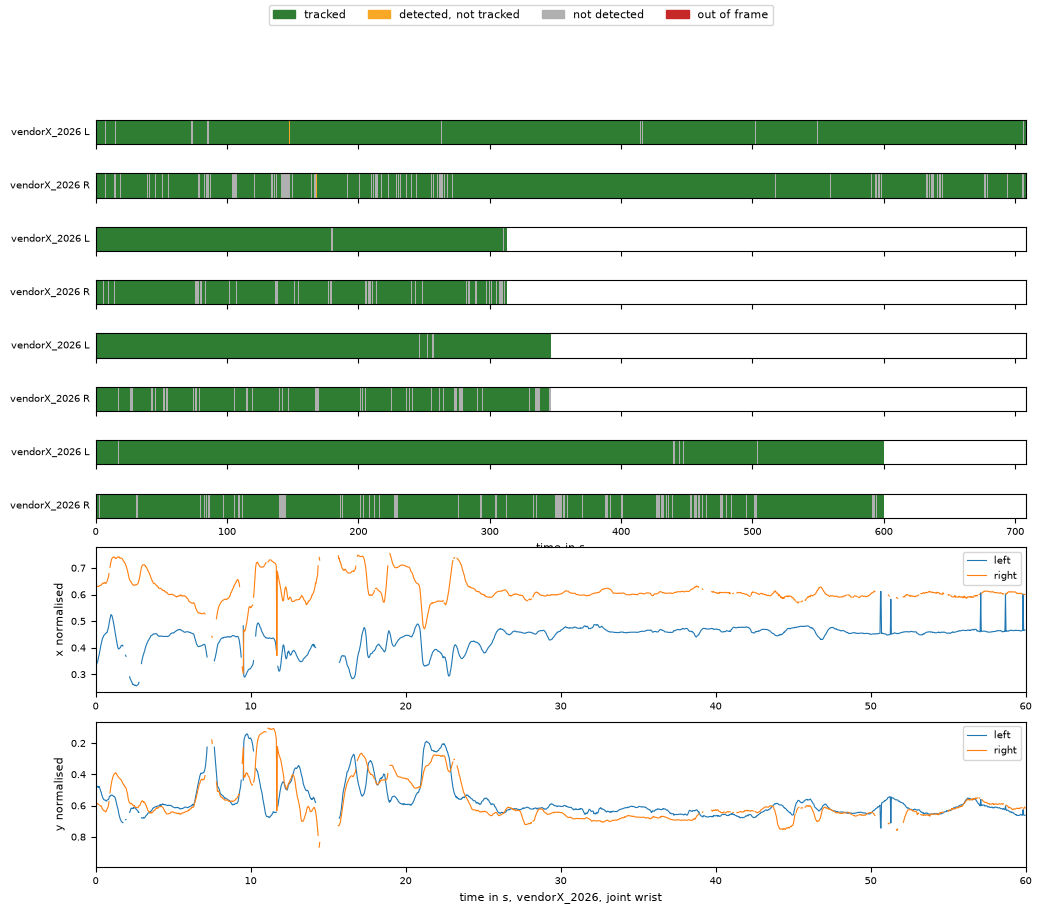

saved 09b_hand_overview.png


In [13]:
colors = ["#2e7d32", "#f9a825", "#b0b0b0", "#c62828"]
labels = ["tracked", "detected, not tracked", "not detected", "out of frame"]
cmap = ListedColormap(colors)


def states(a):
    s = np.full(len(a["det"]), 2)
    s[a["oof"]] = 3
    s[a["det"]] = 1
    s[a["trk"]] = 0
    return s


eps = [ep for ep in ep_ids if ep in prep]
if eps:
    t_all = {ep: (cam_times[ep] - cam_times[ep][0]) / 1e9 for ep in eps}
    tmax = max(t[-1] for t in t_all.values())
    fig = plt.figure(figsize=(12, 0.8 * len(eps) + 6.5))
    gs = fig.add_gridspec(2 * len(eps) + 2, 1, height_ratios=[0.5] * (2 * len(eps)) + [3, 3], hspace=0.6)
    row = 0
    for ep in eps:
        for h in HANDS:
            ax = fig.add_subplot(gs[row])
            ax.imshow(states(prep[ep][h])[None, :], aspect="auto", cmap=cmap, vmin=0, vmax=3,
                      interpolation="nearest", extent=(0, t_all[ep][-1], 0, 1))
            ax.set_xlim(0, tmax)
            ax.set_yticks([])
            ax.set_ylabel(f"{ep[:12]} {h[0].upper()}", rotation=0, ha="right", va="center", fontsize=7)
            ax.tick_params(labelsize=7)
            if row < 2 * len(eps) - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel("time in s", fontsize=8)
            row += 1
    fig.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors, labels)], loc="upper center", ncol=4, fontsize=8)

    # wrist position of the first episode
    ep1 = eps[0]
    wrist = next((i for i, nm in enumerate(layout_names) if "wrist" in nm.lower()), 0)
    t = t_all[ep1]
    m = t <= 60
    for i, (name, ylabel) in enumerate((("x", "x normalised"), ("y", "y normalised"))):
        ax = fig.add_subplot(gs[2 * len(eps) + i])
        for h, c in zip(HANDS, ("#1f77b4", "#ff7f0e")):
            ax.plot(t[m], prep[ep1][h]["pos"][m, wrist, i], lw=0.8, color=c, label=h)
        ax.set_ylabel(ylabel, fontsize=8)
        ax.tick_params(labelsize=7)
        ax.set_xlim(0, min(60, t[-1]))
        if i == 1:
            ax.invert_yaxis()
            ax.set_xlabel(f"time in s, {ep1[:12]}, joint {layout_names[wrist]}", fontsize=8)
        ax.legend(fontsize=7, loc="upper right")
    fig.savefig(REPORTS / "09b_hand_overview.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("saved 09b_hand_overview.png")
else:
    print("no episode with hand arrays, no figure")

## Summary

Writes the summary file and the zip with every 09b file.

In [14]:
def version(name):
    try:
        return imd.version(name)
    except Exception:
        return "unknown"


def plain(o):
    if isinstance(o, (np.integer, np.floating, np.bool_)):
        return o.item()
    return str(o)


ep_out = {}
for ep in ep_ids:
    item = {"build": build_status.get(ep, {"status": "not run"})}
    if ep in new_rows:
        r = new_rows[ep]
        item.update({"size_bytes": int(r["size_bytes"]), "sha256": r["sha256"],
                     "hand_messages_left": int(r["hand_messages_left"]),
                     "hand_messages_right": int(r["hand_messages_right"])})
    if ep in vinfo:
        item["coverage_written"] = vinfo[ep].get("coverage_written")
    ep_out[ep] = item

summary = {
    "python": sys.version.split()[0],
    "versions": {n: version(n) for n in ["mcap", "numpy", "pandas", "matplotlib", "pyyaml", "tqdm", "jsonschema"]},
    "flags": {"FORCE": FORCE, "ROUND_DECIMALS": ROUND_DECIMALS, "SOURCE_FORMAT_TAG": SOURCE_FORMAT_TAG,
              "COVERAGE_FLOOR_PCT": COVERAGE_FLOOR_PCT},
    "hand_source": {"mediapipe_version": mp_version, "strategy": strategy, "handedness_mapping": hmap,
                    "handedness_agreement_pct": hagree, "layout_provisional": layout_provisional},
    "episodes": ep_out,
    "totals": {"size_bytes": int(tot), "hand_payload_bytes": int(payload), "file_growth_bytes": int(growth),
               "gb_per_hour": None if np.isnan(gb_h) else float(gb_h)},
    "tests": hyp.to_dict("records"),
    "check_rows": len(checks),
    "check_rows_failed": int(checks["pass"].eq(False).sum()),
}
(REPORTS / "09b_summary.json").write_text(json.dumps(summary, indent=2, default=plain), encoding="utf-8")

zip_path = REPORTS / "share_09b.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(REPORTS.glob("09b_*")):
        z.write(p, p.name)

built = sum(v["status"] == "built" for v in build_status.values())
skipped = sum(v["status"] == "skipped" for v in build_status.values())
print(f"episodes: {built} built, {skipped} skipped, {nb} failed")
print("results:", ", ".join(f"{k} {v}" for k, v in hyp["result"].value_counts().items()))
print(f"total size {tot / 1e9:.2f} GB, hand channels added {growth / 1e6:.1f} MB")
print("zip:", zip_path)

episodes: 4 built, 0 skipped, 0 failed
results: PASS 12, INFO 3
total size 6.38 GB, hand channels added 345.1 MB
zip: C:\workstation\3RD YEAR\ego_pipeline\reports\share_09b.zip
